# Baseline Model Evaluation: Predicting Job Satisfaction from Background Factors

**Question:** How well can job satisfaction be predicted from *background factors alone* (income, hours, demographics, job context)? This is the bar the person-job fit features must clear in November.

**Data:** NSCG 2023, 79,800 employed college graduates (`data/college_grads_2023/nscg2023_clean.csv`), plus the 6,849-person O*NET-linked subset as the reference sample for fit models.
**Target:** `not_satisfied` = somewhat or very dissatisfied (**9.9%**, about 1 in 10).

## Summary

### Models we tried (full sample, held-out test set of 15,960 people)

| Model | ROC AUC [95% CI] | PR AUC (base rate 0.099) | Balanced accuracy | Recall (dissatisfied) | Accuracy |
|---|---|---|---|---|---|
| Majority class ("always satisfied") | 0.500 | 0.099 | 0.500 | 0.000 | **0.901** ← misleading |
| Logistic regression | 0.626 [0.612, 0.640] | 0.147 | 0.594 | 0.577 | 0.607 |
| KNN (k = 801) | 0.634 [0.620, 0.648] | 0.157 | 0.596 | 0.638 | 0.563 |
| Random forest | 0.651 [0.636, 0.664] | 0.166 | 0.610 | 0.584 | 0.630 |
| **Gradient boosting** | **0.652 [0.637, 0.667]** | **0.170** | **0.613** | 0.530 | 0.680 |

- **Background factors predict dissatisfaction better than chance, but modestly.** The best AUC is 0.65. At the training-chosen threshold, gradient boosting finds 53% of dissatisfied people, with precision of 16% (1.6× the base rate). This is good for **ranking risk**, not for labeling individuals.
- **The non-linear models beat logistic regression** by +0.026 AUC [+0.017, +0.035]. Gradient boosting and random forest are statistically tied, and with survey weights KNN joins the tie. **No single winner should be declared.**
- **`OCEDRLP` (job related to degree) alone adds about +0.02 AUC.** It is kept out of the background baseline because it is a fit-like measure. The team needs to decide where it belongs.
- **On the 25-occupation O*NET subset**, the baseline is about **0.62 AUC [±0.055]** (logistic regression and random forest). Gradient boosting over-fits there (0.59). With only 124 dissatisfied people in the subset test set, **fit gains smaller than ~0.05 AUC won't be detectable from a single split.**

### The three properties

| Property | Check | Result |
|---|---|---|
| **P1. Accuracy:** better than chance on fair metrics | AUC, balanced accuracy and PR AUC lower bounds above chance | ✔ **Passes.** AUC ≥ 0.637, balanced accuracy ≥ 0.600, PR AUC ≥ 0.159 (gradient boosting, 95% lower bounds) |
| **P2. Satisfaction:** risk scores follow real satisfaction | Dissatisfaction rises across risk deciles; scores order the 4 original answers | ✔ **Passes.** 3.9% dissatisfied in the lowest decile → 20.7% in the highest. Mean score: very satisfied 0.425 < somewhat satisfied 0.478 < somewhat dissatisfied 0.518 < very dissatisfied 0.559 |
| **P3. Group correlation:** works across groups, tracks group differences | Per-group AUC; occupation-level correlation; unseen-occupation CV | ✔ **Passes, with caveats.** Group AUCs 0.60–0.67. Occupation-level ρ = 0.72. Only −0.005 AUC on unseen occupations. **Caveat:** at one shared threshold, flag rates differ by group much more than true dissatisfaction rates do |

### Fair measurement when the groups are different sizes

Stratified splits and CV · `class_weight='balanced'` · threshold chosen on out-of-fold **training** predictions (max balanced accuracy) · metrics that ignore the 90/10 ratio (ROC AUC, PR AUC vs base rate, balanced accuracy, minority-class precision/recall/F1) · **stratified bootstrap** CIs that keep the 9.9% rate in every resample · **paired** bootstraps for model differences · survey-weighted check. Details are in Section 1.2.

**Contents:** 1 Evaluation plan · 2 Setup · 3 Data · 4 Models · 5 Results · 6 P1 · 7 P2 · 8 P3 · 9 Survey weights · 10 O*NET subset baseline · 11 Issues, open conversations and crosswalk creation · 12 Save results

## 1. Evaluation plan (decided before looking at test results)

### 1.1 Three properties a good baseline must show

Accuracy alone is misleading here: 90% of people are satisfied, so a model that always says "satisfied" gets 90% accuracy and finds nobody at risk. Instead, each baseline is judged on three properties. Each one has a concrete check.

| # | Property | What it means in plain words | Check used in this notebook |
|---|---|---|---|
| **P1** | **Accuracy: better than chance on fair metrics** | The model ranks dissatisfied people above satisfied people more often than a coin flip, and beats the "always satisfied" model on metrics that are not fooled by the 90/10 split. | ROC AUC 95% CI above 0.5; balanced accuracy above 0.5; PR AUC above the 9.9% base rate. |
| **P2** | **Satisfaction: risk scores follow real satisfaction** | People the model scores as higher risk really are less satisfied. This should hold across risk levels, and across all four original satisfaction answers, even though the model only saw a yes/no target. | Observed dissatisfaction rate rises across predicted-risk deciles; mean risk score rises from *very satisfied* → *very dissatisfied*. |
| **P3** | **Group correlation: works across groups, tracks group differences** | The model is not just good for the largest group (e.g. White, male, private-sector). Where dissatisfaction is higher for a group or occupation, the average predicted risk is also higher. | Per-group AUC and recall for sex, race/ethnicity, sector and occupation group; correlation between occupation-level predicted risk and observed dissatisfaction rate; AUC on occupations the model never saw in training. |

### 1.2 A fair way to measure results when the groups are different sizes

The satisfied group is about **9 times larger** than the dissatisfied group. Every step below is chosen so that this size difference cannot inflate the results:

1. **Target = the minority class.** `not_satisfied = 1` (somewhat or very dissatisfied, 9.9%). Precision, recall and F1 are reported for the group we actually want to find.
2. **Stratified splits.** The 80/20 train/test split and the 5-fold cross-validation keep the 9.9% rate in every piece.
3. **Class weighting in training.** Models use `class_weight='balanced'`, so each dissatisfied person counts about 9 times as much as a satisfied one during fitting. Otherwise models learn to always predict the majority.
4. **Metrics that do not reward the majority:**
   - **ROC AUC**: the chance that a random dissatisfied person is scored higher than a random satisfied person. It does not depend on the 90/10 ratio. 0.5 = chance.
   - **PR AUC (average precision)**: how precise the model stays as it finds more dissatisfied people. Compare it to the base rate (0.099), not to 0.
   - **Balanced accuracy**: the average of recall for each group, so the satisfied and dissatisfied groups count equally. 0.5 = chance.
   - **Recall / precision / F1 for the dissatisfied group**, plus the confusion matrix.
   - Plain **accuracy is shown only to make the point** that it is misleading.
5. **Threshold chosen on training data only.** The cut-off for "flag as at risk" maximizes balanced accuracy (Youden's J) on out-of-fold *training* predictions. The default 0.5 would be arbitrary under class weighting. The test set is never used to choose anything.
6. **Stratified bootstrap confidence intervals.** The test set is resampled 1,000 times *within each class*, so every resample keeps the same 9.9% rate. Model differences use **paired** bootstraps on the same resamples.
7. **Survey weights as a check.** `WTSURVY` is applied at evaluation time to confirm the result represents the U.S. college-graduate workforce, not just the sample.

## 2. Setup

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, GroupKFold, cross_val_predict
from sklearn.metrics import (roc_auc_score, average_precision_score, balanced_accuracy_score, accuracy_score,
                             precision_recall_fscore_support, confusion_matrix, ConfusionMatrixDisplay, roc_curve)

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 40)

SEED = 42
N_BOOT = 1000

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'college_grads_2023').is_dir())
CLEAN = ROOT / 'data/college_grads_2023/nscg2023_clean.csv'
SUBSET = ROOT / 'notebooks/possible data integration/nscg2023_onet30_2_subset.csv'
RESULTS = ROOT / 'results'
RESULTS.mkdir(exist_ok=True)

# Plot style: matches the NSCG and O*NET EDA notebooks
BLUE = '#2a78d6'; GREY = '#b5b3ad'
TEXT = '#0b0b0b'; TEXT2 = '#52514e'; GRID = '#e6e5e1'
mpl.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': TEXT2, 'axes.labelcolor': TEXT2, 'xtick.color': TEXT2, 'ytick.color': TEXT2,
    'axes.titlecolor': TEXT, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
})

## 3. Data and baseline features

**Data:** `nscg2023_clean.csv` from the NSCG EDA notebook: 79,800 employed college graduates with a valid `JOBSATIS`. NSCG imputes item non-response before release, so there are no missing values to handle.

**Baseline features** are the background factors named in the project brief (income, hours, demographics) plus job context. **No work values, O*NET or fit information is used here.**

| Type | Features |
|---|---|
| Numeric (standardized) | `log_SALARY` (salary is very right-skewed), `HRSWK`, `AGE` |
| Categorical (one-hot) | `SEX_2023`, `RACETHM`, `DGRDG` (degree), `EMSECSM` (sector), `EMSIZE` (employer size), `SUPWK` (supervises others), `MARIND` (married) |

**`OCEDRLP` (job related to degree) is held out of the main baseline.** The EDA notebook flagged it as a crude person-job fit measure. Putting it in the baseline would hide part of the fit effect that November is meant to measure. It is reported separately as **Baseline + OCEDRLP** so the team can see its size and decide (see Section 10).

The `sat_*` facet-satisfaction columns are never used: they are nearly the same question as the target.

In [2]:
df = pd.read_csv(CLEAN, low_memory=False)
df['log_SALARY'] = np.log1p(df['SALARY'])
NUM = ['log_SALARY', 'HRSWK', 'AGE']
CAT = ['SEX_2023', 'RACETHM', 'DGRDG', 'EMSECSM', 'EMSIZE', 'SUPWK', 'MARIND']
for c in CAT + ['OCEDRLP']:
    df[c] = df[c].astype(str)
FEATURE_SETS = {'Baseline': (NUM, CAT), 'Baseline + OCEDRLP': (NUM, CAT + ['OCEDRLP'])}

# Labels from the NSCG 2023 codebook (Ppcg23.sas), used only for readable group tables
LABELS = {
    'SEX_2023': {'F': 'Female', 'M': 'Male'},
    'RACETHM': {'1': 'Asian', '2': 'American Indian/Alaska Native', '3': 'Black', '4': 'Hispanic',
                '5': 'White', '6': 'Native Hawaiian/Pacific Islander', '7': 'Multiple race'},
    'EMSECSM': {'1': 'Educational institution', '2': 'Government', '3': 'Business/industry'},
    'N2OCPRMG': {1: 'Computer & math scientists', 2: 'Life scientists', 3: 'Physical scientists',
                 4: 'Social scientists', 5: 'Engineers', 6: 'S&E-related', 7: 'Non-S&E'},
}

y = (1 - df['satisfied']).to_numpy()          # 1 = not satisfied (the minority we want to find)
w = df['WTSURVY'].to_numpy()
train_idx, test_idx = train_test_split(df.index, test_size=0.2, stratify=y, random_state=SEED)
y_tr, y_te, w_te = y[train_idx], y[test_idx], w[test_idx]

pd.DataFrame({'people': [len(df), len(train_idx), len(test_idx)],
              'not satisfied': [y.sum(), y_tr.sum(), y_te.sum()],
              '% not satisfied': [y.mean() * 100, y_tr.mean() * 100, y_te.mean() * 100]},
             index=['all', 'train (80%)', 'test (20%)']).round(2)

,people,not satisfied,% not satisfied
all,79800,7881,9.88
train (80%),63840,6305,9.88
test (20%),15960,1576,9.87


**Observation:** The stratified split keeps the dissatisfied share at 9.9% in both train and test. The test set has about 1,580 dissatisfied people, enough for stable AUC estimates.

## 4. Models we tried

| Model | Why it is here | Imbalance handling | Settings |
|---|---|---|---|
| **Majority class (dummy)** | The floor. It always predicts "satisfied" and shows what a useless model scores on each metric. | none | `strategy='prior'` |
| **Logistic regression** | Simple, interpretable, and the reference model for the November comparison. | `class_weight='balanced'` | L2, default C |
| **Random forest** | Captures interactions (e.g. salary × sector) without manual feature engineering. | `class_weight='balanced_subsample'` | 300 trees, `min_samples_leaf=50` |
| **Gradient boosting** (`HistGradientBoosting`) | Usually the strongest tabular model; fast on 80k rows. | `class_weight='balanced'` | lr 0.05, 300 rounds, 15 leaves, `min_samples_leaf=100` |
| **K-nearest neighbors** | Carried over from the team's earlier KNN notebook for comparison. KNN has no class weights, so only its ranking (AUC) and the tuned threshold make it fair. | threshold only | k = 801 (best k from the KNN notebook's CV grid), uniform weights |

Tree settings are deliberately conservative (large leaves) rather than tuned, so that the baseline is not over-fit to this split. Every model uses the same split, preprocessing and threshold rule.

In [3]:
def preprocessor(num, cat):
    return ColumnTransformer([('num', StandardScaler(), num),
                              ('cat', OneHotEncoder(handle_unknown='ignore'), cat)])

MODELS = {
    'Majority class': lambda: DummyClassifier(strategy='prior'),
    'Logistic regression': lambda: LogisticRegression(class_weight='balanced', max_iter=2000),
    'Random forest': lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=50, class_weight='balanced_subsample',
                                                    n_jobs=-1, random_state=SEED),
    'Gradient boosting': lambda: HistGradientBoostingClassifier(class_weight='balanced', learning_rate=0.05, max_iter=300,
                                                                max_leaf_nodes=15, min_samples_leaf=100,
                                                                l2_regularization=1.0, random_state=SEED),
    'KNN': lambda: KNeighborsClassifier(n_neighbors=801, n_jobs=-1),
}

def make_pipeline(model, num, cat):
    return Pipeline([('pre', preprocessor(num, cat)), ('model', MODELS[model]())])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def youden_threshold(y_true, p):
    # cut-off that maximizes balanced accuracy (TPR - FPR) on training predictions
    fpr, tpr, thr = roc_curve(y_true, p)
    return float(thr[np.argmax(tpr - fpr)])

def fit_and_score(model, num, cat):
    pipe = make_pipeline(model, num, cat)
    oof = cross_val_predict(pipe, df.loc[train_idx], y_tr, cv=cv, method='predict_proba')[:, 1]
    pipe.fit(df.loc[train_idx], y_tr)
    return {'pipe': pipe, 'oof': oof, 'p': pipe.predict_proba(df.loc[test_idx])[:, 1],
            'threshold': youden_threshold(y_tr, oof) if len(np.unique(oof)) > 1 else 1.0}

In [4]:
runs = {}
for fs, (num, cat) in FEATURE_SETS.items():
    models = MODELS if fs == 'Baseline' else ['Logistic regression', 'Gradient boosting']
    for model in models:
        t = time.time()
        runs[(fs, model)] = fit_and_score(model, num, cat)
        print(f'{fs:20s} {model:20s} {time.time() - t:5.1f}s')

Baseline             Majority class         0.3s


Baseline             Logistic regression    0.5s


Baseline             Random forest          7.4s


Baseline             Gradient boosting      5.4s


Baseline             KNN                    6.7s


Baseline + OCEDRLP   Logistic regression    0.5s


Baseline + OCEDRLP   Gradient boosting      5.6s


## 5. Results on fair metrics

### 5.1 Point estimates

`CV AUC` is from 5-fold cross-validation on the training set. All other columns are computed on the held-out test set. Precision, recall and F1 refer to the **dissatisfied** group, at the threshold chosen on training data.

In [5]:
def metrics(y_true, p, thr, weights=None):
    pred = (p >= thr).astype(int)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, pred, average='binary', zero_division=0, sample_weight=weights)
    return {'ROC AUC': roc_auc_score(y_true, p, sample_weight=weights),
            'PR AUC': average_precision_score(y_true, p, sample_weight=weights),
            'balanced acc': balanced_accuracy_score(y_true, pred, sample_weight=weights),
            'accuracy': accuracy_score(y_true, pred, sample_weight=weights),
            'precision': prec, 'recall': rec, 'F1': f1,
            'flagged %': np.average(pred, weights=weights) * 100}

rows = []
for (fs, model), r in runs.items():
    rows.append({'features': fs, 'model': model, 'CV AUC': roc_auc_score(y_tr, r['oof']),
                 **metrics(y_te, r['p'], r['threshold']), 'threshold': r['threshold']})
results = pd.DataFrame(rows).set_index(['features', 'model'])
results.round(3)

CV AUC  ROC AUC  PR AUC  balanced acc  accuracy  precision  recall     F1  flagged %  threshold
features           model                                                                                                               
Baseline           Majority class        0.500    0.500   0.099         0.500     0.901      0.000   0.000  0.000      0.000      1.000
                   Logistic regression   0.636    0.626   0.147         0.594     0.607      0.140   0.577  0.225     40.796      0.498
                   Random forest         0.651    0.651   0.166         0.610     0.630      0.149   0.584  0.238     38.697      0.478
                   Gradient boosting     0.657    0.652   0.170         0.613     0.680      0.161   0.530  0.247     32.594      0.524
                   KNN                   0.637    0.634   0.157         0.596     0.563      0.136   0.638  0.224     46.479      0.090
Baseline + OCEDRLP Logistic regression   0.655    0.652   0.172         0.607     0.609      0.145   0.603  0.234     41.096      0.492
                   Gradient boosting     0.668    0.668   0.190         0.618     0.614      0.150   0.622  0.242     40.959      0.485

**Observation:** The **accuracy** column shows why accuracy can't be the headline metric. The majority-class model has the highest accuracy (0.901) and finds **zero** dissatisfied people. Every real model has *lower* accuracy, because it trades some satisfied people for finding over half of the dissatisfied ones.

On the fair metrics, every real model beats the floor, but only by a modest margin. **Gradient boosting** and **random forest** rank highest. Logistic regression and KNN trail by about 0.02–0.03 AUC. CV AUC and test AUC agree within about 0.01 for every model, so the split is not producing a lucky result.

### 5.2 Confidence intervals (stratified bootstrap)

Each of the 1,000 resamples draws dissatisfied and satisfied test cases separately, so every resample keeps the 9.9% rate.

In [6]:
rng = np.random.default_rng(SEED)
pos, neg = np.flatnonzero(y_te == 1), np.flatnonzero(y_te == 0)
BOOT = [np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(N_BOOT)]

def boot_ci(stat):
    vals = np.array([stat(b) for b in BOOT])
    return vals, np.percentile(vals, [2.5, 97.5])

def fmt(est, ci):
    return f'{est:.3f} [{ci[0]:.3f}, {ci[1]:.3f}]'

ci_rows = []
for (fs, model), r in runs.items():
    p, pred = r['p'], (r['p'] >= r['threshold']).astype(int)
    row = {'features': fs, 'model': model}
    for name, f in [('ROC AUC', lambda b: roc_auc_score(y_te[b], p[b])),
                    ('PR AUC', lambda b: average_precision_score(y_te[b], p[b])),
                    ('balanced acc', lambda b: balanced_accuracy_score(y_te[b], pred[b]))]:
        r[f'boot {name}'], ci = boot_ci(f)
        row[name] = fmt(results.loc[(fs, model), name], ci)
    ci_rows.append(row)
ci_table = pd.DataFrame(ci_rows).set_index(['features', 'model'])
ci_table

ROC AUC                PR AUC          balanced acc
features           model                                                                                
Baseline           Majority class       0.500 [0.500, 0.500]  0.099 [0.099, 0.099]  0.500 [0.500, 0.500]
                   Logistic regression  0.626 [0.612, 0.640]  0.147 [0.140, 0.157]  0.594 [0.580, 0.606]
                   Random forest        0.651 [0.636, 0.664]  0.166 [0.156, 0.179]  0.610 [0.596, 0.622]
                   Gradient boosting    0.652 [0.637, 0.667]  0.170 [0.159, 0.182]  0.613 [0.600, 0.626]
                   KNN                  0.634 [0.620, 0.648]  0.157 [0.147, 0.168]  0.596 [0.584, 0.608]
Baseline + OCEDRLP Logistic regression  0.652 [0.638, 0.666]  0.172 [0.162, 0.184]  0.607 [0.594, 0.618]
                   Gradient boosting    0.668 [0.653, 0.682]  0.190 [0.177, 0.205]  0.618 [0.605, 0.630]

In [7]:
def paired_delta(a, b, label):
    # AUC(b) - AUC(a) on the same bootstrap resamples
    d = runs[b]['boot ROC AUC'] - runs[a]['boot ROC AUC']
    est = results.loc[b, 'ROC AUC'] - results.loc[a, 'ROC AUC']
    lo, hi = np.percentile(d, [2.5, 97.5])
    return {'comparison': label, 'ΔAUC': round(est, 3), '95% CI': f'[{lo:+.3f}, {hi:+.3f}]',
            'share of resamples > 0': round((d > 0).mean(), 3)}

B = 'Baseline'
deltas = pd.DataFrame([
    paired_delta((B, 'Logistic regression'), (B, 'Gradient boosting'), 'Gradient boosting vs logistic regression'),
    paired_delta((B, 'Random forest'), (B, 'Gradient boosting'), 'Gradient boosting vs random forest'),
    paired_delta((B, 'KNN'), (B, 'Gradient boosting'), 'Gradient boosting vs KNN'),
    paired_delta((B, 'Logistic regression'), ('Baseline + OCEDRLP', 'Logistic regression'), 'Logistic regression: add OCEDRLP'),
    paired_delta((B, 'Gradient boosting'), ('Baseline + OCEDRLP', 'Gradient boosting'), 'Gradient boosting: add OCEDRLP'),
]).set_index('comparison')
deltas

,ΔAUC,95% CI,share of resamples > 0
comparison,,,
Gradient boosting vs logistic regression,0.026,"[+0.017, +0.035]",1.000
Gradient boosting vs random forest,0.002,"[-0.004, +0.007]",0.725
Gradient boosting vs KNN,0.018,"[+0.010, +0.027]",1.000
Logistic regression: add OCEDRLP,0.026,"[+0.017, +0.034]",1.000
Gradient boosting: add OCEDRLP,0.016,"[+0.009, +0.023]",1.000


**Observation:** Gradient boosting beats logistic regression and KNN by a clear margin, with paired intervals that exclude zero. It is statistically tied with random forest. The tree models gain from interactions that a linear model with main effects can't express.

Adding `OCEDRLP` alone raises AUC by about +0.02 for both models. That is a large gain for one variable, and it supports keeping it out of the "background only" baseline (Section 10).

**Reference models for November:** on the full sample, **gradient boosting** (or the statistically tied random forest) is the strongest baseline, and **logistic regression** is the interpretable reference. Fit-feature models should be compared against both, on this same split and with the same bootstrap. The subset results in Section 10 change this picture.

### 5.3 ROC and precision-recall curves

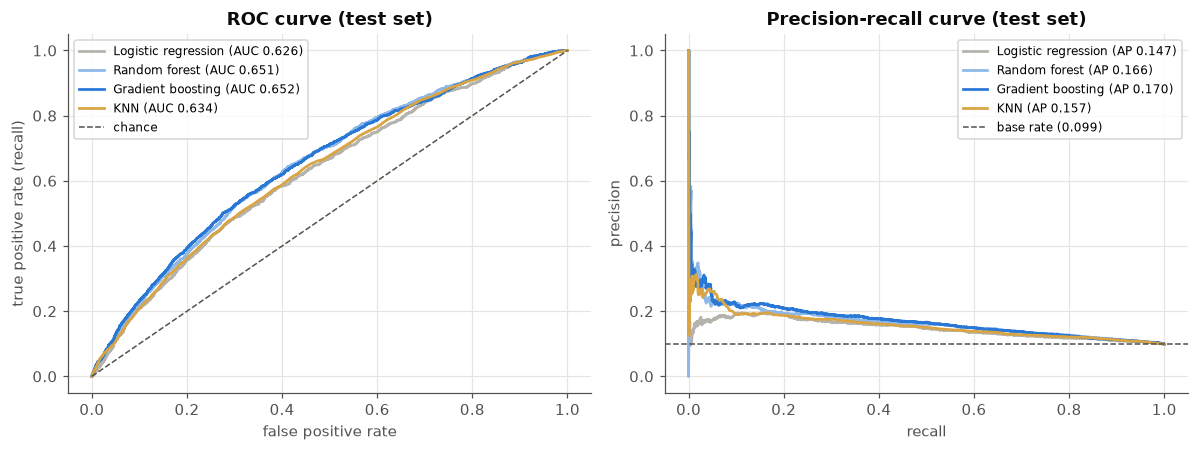

In [8]:
from sklearn.metrics import precision_recall_curve
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
colors = {'Logistic regression': GREY, 'Random forest': '#8fb8ea', 'Gradient boosting': BLUE, 'KNN': '#d9a441'}
for model, color in colors.items():
    p = runs[(B, model)]['p']
    fpr, tpr, _ = roc_curve(y_te, p)
    prec, rec, _ = precision_recall_curve(y_te, p)
    axes[0].plot(fpr, tpr, color=color, lw=1.8, label=f'{model} (AUC {roc_auc_score(y_te, p):.3f})')
    axes[1].plot(rec, prec, color=color, lw=1.8, label=f'{model} (AP {average_precision_score(y_te, p):.3f})')
axes[0].plot([0, 1], [0, 1], color=TEXT2, ls='--', lw=1, label='chance')
axes[0].set_xlabel('false positive rate'); axes[0].set_ylabel('true positive rate (recall)')
axes[1].set_xlabel('recall'); axes[1].set_ylabel('precision')
axes[1].axhline(y_te.mean(), color=TEXT2, ls='--', lw=1, label=f'base rate ({y_te.mean():.3f})')
axes[0].set_title('ROC curve (test set)'); axes[1].set_title('Precision-recall curve (test set)')
axes[1].legend(fontsize=8); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Observation:** All four ROC curves sit above the chance line, and the tree models sit on top for most of the range. In the precision-recall plot, gradient boosting's precision is about 0.30 among the 1% of people it scores highest and about 0.21 in the top 10%. After that it slides toward the 0.099 base rate. Background factors can point to a small higher-risk group, but most dissatisfied people look like everyone else on these variables.

## 6. Property P1: accuracy (better than chance on fair metrics)

Using the best baseline (gradient boosting) and the interpretable reference (logistic regression).

In [9]:
def p1_check(model):
    r = runs[(B, model)]
    auc_lo = np.percentile(r['boot ROC AUC'], 2.5)
    ba_lo = np.percentile(r['boot balanced acc'], 2.5)
    pr_lo = np.percentile(r['boot PR AUC'], 2.5)
    return {'model': model,
            'AUC lower bound > 0.5': f'{auc_lo:.3f}  ' + ('✔' if auc_lo > 0.5 else '✘'),
            'balanced acc lower bound > 0.5': f'{ba_lo:.3f}  ' + ('✔' if ba_lo > 0.5 else '✘'),
            f'PR AUC lower bound > base rate {y_te.mean():.3f}': f'{pr_lo:.3f}  ' + ('✔' if pr_lo > y_te.mean() else '✘')}

pd.DataFrame([p1_check(m) for m in ['Gradient boosting', 'Logistic regression']]).set_index('model')

,AUC lower bound > 0.5,balanced acc lower bound > 0.5,PR AUC lower bound > base rate 0.099
model,,,
Gradient boosting,0.637 ✔,0.600 ✔,0.159 ✔
Logistic regression,0.612 ✔,0.580 ✔,0.140 ✔


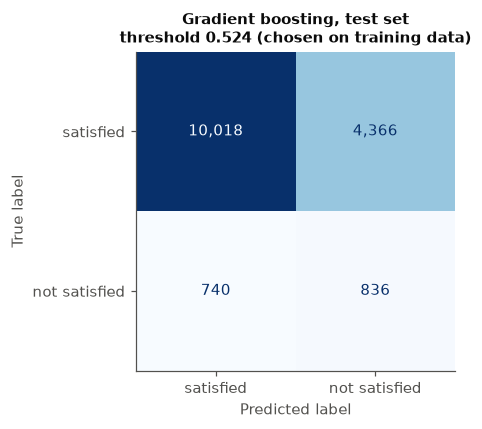

found 836 of 1,576 dissatisfied (recall 53.0%); flagged 4,366 satisfied people too (precision 16.1%, 1.6x the base rate)


In [10]:
r = runs[(B, 'Gradient boosting')]
pred = (r['p'] >= r['threshold']).astype(int)
fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=['satisfied', 'not satisfied']).plot(
    ax=ax, colorbar=False, values_format=',', cmap='Blues')
ax.set_title(f'Gradient boosting, test set\nthreshold {r["threshold"]:.3f} (chosen on training data)', fontsize=10)
ax.grid(False); plt.tight_layout(); plt.show()
tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
print(f'found {tp:,} of {tp + fn:,} dissatisfied (recall {tp / (tp + fn):.1%}); '
      f'flagged {fp:,} satisfied people too (precision {tp / (tp + fp):.1%}, {tp / (tp + fp) / y_te.mean():.1f}x the base rate)')

**P1 verdict: passes.** All three lower bounds clear their chance level for both models. The size of the effect is modest, though. At the chosen threshold the model finds roughly half of the dissatisfied people, but most people it flags are actually satisfied. Precision is only about 1.6× the base rate. Background factors are good for **ranking risk**, not for confidently labeling an individual.

## 7. Property P2: satisfaction (risk scores follow real satisfaction)

**Note on probabilities.** With `class_weight='balanced'`, a score of 0.5 does *not* mean a 50% chance of being dissatisfied. Training reweights the classes, so scores are inflated. This section therefore checks **ordering** (do higher scores mean less satisfied people?), which is what AUC relies on. If calibrated probabilities are needed later, they can be rescaled with `CalibratedClassifierCV`.

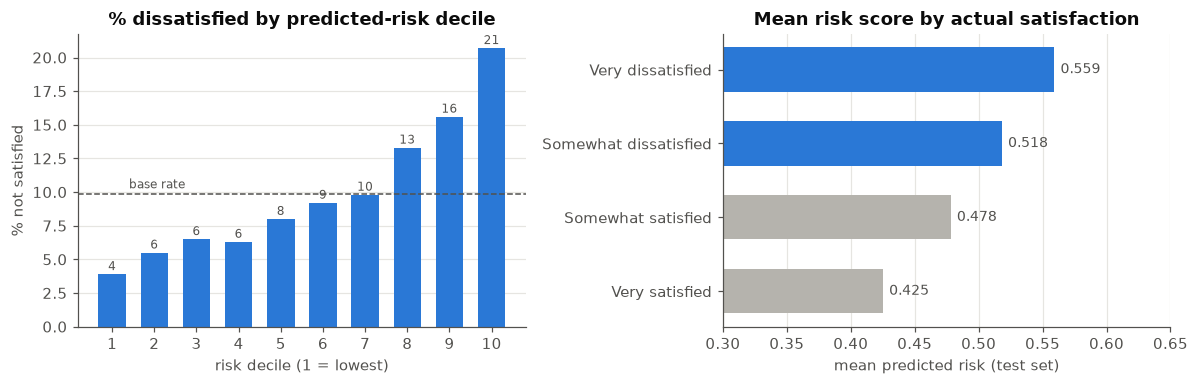

,people,dissatisfied,rate %,lift vs base rate
risk decile,,,,
1,1596,62,3.9,0.39
2,1596,88,5.5,0.56
3,1596,104,6.5,0.66
4,1596,100,6.3,0.64
5,1596,127,8.0,0.81
6,1596,147,9.2,0.93
7,1596,156,9.8,0.99
8,1596,212,13.3,1.35
9,1596,249,15.6,1.58


,people,mean risk score,median risk score
job_satisfaction,,,
Very satisfied,7075,0.425,0.417
Somewhat satisfied,7309,0.478,0.469
Somewhat dissatisfied,1236,0.518,0.522
Very dissatisfied,340,0.559,0.581


In [11]:
r = runs[(B, 'Gradient boosting')]
test = df.loc[test_idx].assign(risk=r['p'], not_satisfied=y_te)
test['risk decile'] = pd.qcut(test['risk'].rank(method='first'), 10, labels=range(1, 11))
dec = test.groupby('risk decile', observed=True).agg(people=('not_satisfied', 'size'),
                                                     dissatisfied=('not_satisfied', 'sum'),
                                                     rate=('not_satisfied', 'mean'))
dec['rate %'] = (dec.pop('rate') * 100).round(1)
dec['lift vs base rate'] = (dec['rate %'] / (y_te.mean() * 100)).round(2)

SAT_LABELS = {4: 'Very satisfied', 3: 'Somewhat satisfied', 2: 'Somewhat dissatisfied', 1: 'Very dissatisfied'}
by_level = (test.groupby('job_satisfaction')['risk'].agg(['size', 'mean', 'median'])
                .rename(index=SAT_LABELS).iloc[::-1].round(3))
by_level.columns = ['people', 'mean risk score', 'median risk score']

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(dec.index.astype(str), dec['rate %'], color=BLUE, width=0.65)
axes[0].axhline(y_te.mean() * 100, color=TEXT2, ls='--', lw=1)
axes[0].text(0.4, y_te.mean() * 100 + 0.4, 'base rate', color=TEXT2, fontsize=8)
for x, v in enumerate(dec['rate %']):
    axes[0].text(x, v + 0.3, f'{v:.0f}', ha='center', color=TEXT2, fontsize=8)
axes[0].set_title('% dissatisfied by predicted-risk decile'); axes[0].set_xlabel('risk decile (1 = lowest)')
axes[0].set_ylabel('% not satisfied'); axes[0].grid(axis='x', visible=False)
axes[1].barh(by_level.index, by_level['mean risk score'], color=[GREY, GREY, BLUE, BLUE], height=0.6)
for yy, v in enumerate(by_level['mean risk score']):
    axes[1].text(v + 0.005, yy, f'{v:.3f}', va='center', color=TEXT2, fontsize=9)
axes[1].set_title('Mean risk score by actual satisfaction'); axes[1].set_xlim(0.3, 0.65)
axes[1].set_xlabel('mean predicted risk (test set)'); axes[1].grid(axis='y', visible=False)
plt.tight_layout(); plt.show()
display(dec)
by_level

**P2 verdict: passes.** The observed dissatisfaction rate rises across the risk deciles, with only a negligible dip between deciles 3 and 4: from 3.9% in the lowest decile to 20.7% in the highest. That is about **5× the lowest decile and 2.1× the base rate**. The mean risk score also lines up with all four original answers: *very satisfied* (0.425) < *somewhat satisfied* (0.478) < *somewhat dissatisfied* (0.518) < *very dissatisfied* (0.559). The model was only trained on the yes/no split, so this ordering is learned, not built in. The dissatisfied group is not a random 10%: background factors pick up a real gradient.

The steps between neighboring answers are similar in size (about 0.04–0.05). Background factors shift risk gradually across the whole satisfaction scale, not just at the satisfied/dissatisfied line. That supports the option of an ordinal or *very satisfied vs rest* target later (Section 11.3).

## 8. Property P3: group correlation (works across groups, tracks group differences)

### 8.1 Performance within groups

AUC is computed *inside* each group (dissatisfied vs satisfied people of the same sex, race, etc.), with the same stratified bootstrap. Recall and flag rate use the single global threshold, so differences show who the model over- or under-flags.

In [12]:
def group_table(col, model='Gradient boosting', min_pos=20):
    r = runs[(B, model)]
    g = df.loc[test_idx, col].astype(str).to_numpy()
    p, pred = r['p'], (r['p'] >= r['threshold']).astype(int)
    labels = {str(k): v for k, v in LABELS.get(col, {}).items()}
    rows, rng_g = [], np.random.default_rng(SEED)
    for level in sorted(np.unique(g)):
        m = g == level
        yp, pp, dp = y_te[m], p[m], pred[m]
        row = {'group': labels.get(level, level), 'people': int(m.sum()), 'dissatisfied': int(yp.sum()),
               '% dissatisfied': round(yp.mean() * 100, 1), 'flagged %': round(dp.mean() * 100, 1),
               'recall': round(dp[yp == 1].mean(), 3) if yp.sum() else np.nan}
        if yp.sum() >= min_pos:
            ip, ineg = np.flatnonzero(yp == 1), np.flatnonzero(yp == 0)
            boots = [np.concatenate([rng_g.choice(ip, len(ip)), rng_g.choice(ineg, len(ineg))]) for _ in range(300)]
            vals = [roc_auc_score(yp[b], pp[b]) for b in boots]
            row['AUC [95% CI]'] = fmt(roc_auc_score(yp, pp), np.percentile(vals, [2.5, 97.5]))
        else:
            row['AUC [95% CI]'] = f'too few (<{min_pos} dissatisfied)'
        rows.append(row)
    return pd.DataFrame(rows).set_index('group')

print(f"Overall test AUC (gradient boosting): {fmt(results.loc[(B, 'Gradient boosting'), 'ROC AUC'], np.percentile(runs[(B, 'Gradient boosting')]['boot ROC AUC'], [2.5, 97.5]))}")
for col in ['SEX_2023', 'RACETHM', 'EMSECSM', 'N2OCPRMG']:
    print(f'\n{col}')
    display(group_table(col))

Overall test AUC (gradient boosting): 0.652 [0.637, 0.667]

SEX_2023


,people,dissatisfied,% dissatisfied,flagged %,recall,AUC [95% CI]
group,,,,,,
Female,7295,768,10.5,38.7,0.617,"0.665 [0.648, 0.685]"
Male,8665,808,9.3,27.4,0.448,"0.638 [0.619, 0.657]"



RACETHM


,people,dissatisfied,% dissatisfied,flagged %,recall,AUC [95% CI]
group,,,,,,
Asian,3185,316,9.9,31.8,0.513,"0.647 [0.620, 0.679]"
American Indian/Alaska Native,58,7,12.1,46.6,0.429,too few (<20 dissatisfied)
Black,1292,170,13.2,54.6,0.735,"0.620 [0.579, 0.663]"
Hispanic,2101,200,9.5,43.8,0.665,"0.669 [0.633, 0.704]"
White,8761,809,9.2,26.0,0.452,"0.654 [0.635, 0.672]"
Native Hawaiian/Pacific Islander,14,4,28.6,50.0,0.750,too few (<20 dissatisfied)
Multiple race,549,70,12.8,45.9,0.629,"0.610 [0.538, 0.673]"



EMSECSM


,people,dissatisfied,% dissatisfied,flagged %,recall,AUC [95% CI]
group,,,,,,
Educational institution,3052,327,10.7,41.5,0.578,"0.630 [0.601, 0.664]"
Government,1907,166,8.7,26.0,0.428,"0.622 [0.573, 0.666]"
Business/industry,11001,1083,9.8,31.3,0.532,"0.660 [0.642, 0.677]"



N2OCPRMG


,people,dissatisfied,% dissatisfied,flagged %,recall,AUC [95% CI]
group,,,,,,
Computer & math scientists,2083,221,10.6,22.3,0.376,"0.603 [0.561, 0.641]"
Life scientists,757,66,8.7,36.6,0.500,"0.637 [0.582, 0.691]"
Physical scientists,518,48,9.3,28.8,0.375,"0.602 [0.513, 0.686]"
Social scientists,492,38,7.7,33.5,0.526,"0.656 [0.570, 0.733]"
Engineers,1913,148,7.7,18.6,0.324,"0.622 [0.577, 0.672]"
S&E-related,3694,308,8.3,31.7,0.529,"0.652 [0.619, 0.683]"
Non-S&E,6503,747,11.5,40.3,0.631,"0.670 [0.653, 0.691]"


**Observation:** Within-group AUC stays in a 0.60–0.67 band for every group large enough to measure, and every group's interval overlaps the overall 0.652 [0.637, 0.667]. *Ranking* quality is fairly even across groups. It is somewhat weaker inside computer/math, physical science and engineering jobs (about 0.60–0.62) than inside non-S&E jobs (0.670). The two smallest race groups (American Indian/Alaska Native, Native Hawaiian/Pacific Islander) have too few dissatisfied people in the test set to evaluate. Merge them or use cross-validated predictions if a fairness check for them is needed.

**Flag rates differ by group much more than actual dissatisfaction does.** Black respondents are dissatisfied at 13.2% vs 9.2% for White respondents, but are flagged at 54.6% vs 26.0%. Women are dissatisfied at 10.5% vs 9.3% for men, but are flagged at 38.7% vs 27.4%. With only background features, group membership itself is one of the strongest signals. A single threshold therefore magnifies group differences, and recall swings with it (0.74 for Black vs 0.45 for White respondents; 0.32 for engineers vs 0.63 for non-S&E). This is fine for a risk-ranking benchmark. If a model like this were ever used to act on individuals, it would need per-group threshold review.

### 8.2 Does predicted risk track group-level dissatisfaction?

Here each **occupation** (`N3OCPR`, 129 codes) is one data point. Occupation-level analysis needs more people per occupation than the test set has, so it uses **out-of-fold predictions for all 79,800 people** (5-fold CV: each person is scored by a model that never saw them). Occupation is **not** a model feature, so any correlation comes from the background factors alone.

112 occupations with ≥100 people | Spearman ρ = 0.72 | Pearson r = 0.78


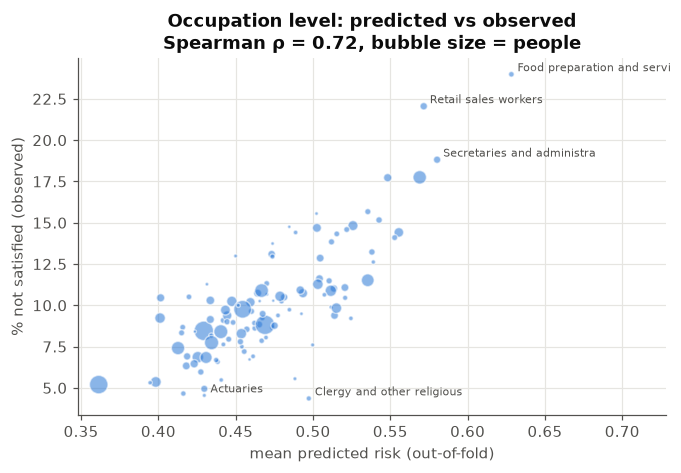

In [13]:
gb_pipe = make_pipeline('Gradient boosting', NUM, CAT)
df['oof_risk'] = cross_val_predict(gb_pipe, df, y, cv=cv, method='predict_proba')[:, 1]
df['not_satisfied'] = y
occ = (df.groupby(['N3OCPR', 'occupation'])
         .agg(people=('not_satisfied', 'size'), observed=('not_satisfied', 'mean'), predicted=('oof_risk', 'mean'))
         .query('people >= 100').reset_index())
rho = occ[['observed', 'predicted']].corr(method='spearman').iloc[0, 1]
r_p = occ[['observed', 'predicted']].corr().iloc[0, 1]
print(f'{len(occ)} occupations with ≥100 people | Spearman ρ = {rho:.2f} | Pearson r = {r_p:.2f}')

fig, ax = plt.subplots(figsize=(6.4, 4.4))
ax.scatter(occ['predicted'], occ['observed'] * 100, s=occ['people'] / 25, color=BLUE, alpha=0.55, edgecolor='white')
for _, row in pd.concat([occ.nlargest(3, 'observed'), occ.nsmallest(2, 'observed')]).iterrows():
    ax.annotate(row['occupation'][:26], (row['predicted'], row['observed'] * 100), fontsize=7, color=TEXT2,
                xytext=(4, 2), textcoords='offset points')
ax.set_xlim(right=occ['predicted'].max() + 0.1)
ax.set_xlabel('mean predicted risk (out-of-fold)'); ax.set_ylabel('% not satisfied (observed)')
ax.set_title(f'Occupation level: predicted vs observed\nSpearman ρ = {rho:.2f}, bubble size = people')
plt.tight_layout(); plt.show()

**Observation:** Across 112 occupations with at least 100 people, mean predicted risk correlates strongly with the observed dissatisfaction rate (Spearman ρ = 0.72). The model was never told anyone's occupation, so **most of the difference between more- and less-satisfied occupations is already explained by who works in them and what they are paid**. Some spread remains: occupations with similar predicted risk still differ by a few points. That leftover variation is what occupation-level O*NET features in November would need to explain. Because background factors already capture so much of the occupation pattern, O*NET features should be judged by their gain *over* this baseline, not by their raw correlation with satisfaction.

### 8.3 Generalizing to occupations the model never saw

The O*NET fit features in November are occupation-level, so it matters whether the baseline only works because it memorizes occupation-specific patterns. `GroupKFold` keeps every occupation entirely in either the training folds or the held-out fold. A large drop compared with the ordinary stratified CV would mean results don't transfer to new occupations.

In [14]:
gkf = GroupKFold(n_splits=5)
rows = []
for model in ['Logistic regression', 'Gradient boosting']:
    pipe = make_pipeline(model, NUM, CAT)
    strat = cross_val_predict(pipe, df, y, cv=cv, method='predict_proba')[:, 1]
    grouped = cross_val_predict(pipe, df, y, cv=gkf, groups=df['N3OCPR'], method='predict_proba')[:, 1]
    rows.append({'model': model, 'stratified 5-fold AUC': roc_auc_score(y, strat),
                 'occupation-grouped 5-fold AUC': roc_auc_score(y, grouped)})
grouped_cv = pd.DataFrame(rows).set_index('model')
grouped_cv['drop'] = grouped_cv.iloc[:, 0] - grouped_cv.iloc[:, 1]
grouped_cv.round(3)

,stratified 5-fold AUC,occupation-grouped 5-fold AUC,drop
model,,,
Logistic regression,0.634,0.632,0.002
Gradient boosting,0.657,0.653,0.005


**Observation:** AUC drops by only 0.002–0.005 when whole occupations are held out, so the baseline is not leaning on occupation-specific patterns.

**P3 verdict: passes, with caveats.** Ranking quality holds within every measurable group. Predicted risk tracks occupation-level dissatisfaction (ρ = 0.72), and performance transfers to unseen occupations. The caveats: the two smallest race groups can't be evaluated on one test split, and at a shared threshold flag rates and recall differ by group much more than true dissatisfaction rates do.

## 9. Survey-weighted check

KNN and the other sklearn models were trained unweighted. Here the test metrics are recomputed with `WTSURVY` to check that the results represent the U.S. college-graduate workforce rather than the NSCG sample design, which oversamples some groups.

In [15]:
rows = []
for (fs, model), r in runs.items():
    if model == 'Majority class':
        continue
    uw, wt = metrics(y_te, r['p'], r['threshold']), metrics(y_te, r['p'], r['threshold'], w_te)
    rows.append({'features': fs, 'model': model, 'AUC': uw['ROC AUC'], 'weighted AUC': wt['ROC AUC'],
                 'balanced acc': uw['balanced acc'], 'weighted balanced acc': wt['balanced acc'],
                 'recall': uw['recall'], 'weighted recall': wt['recall']})
pd.DataFrame(rows).set_index(['features', 'model']).round(3)

AUC  weighted AUC  balanced acc  weighted balanced acc  recall  weighted recall
features           model                                                                                                 
Baseline           Logistic regression  0.626         0.663         0.594                  0.630   0.577            0.626
                   Random forest        0.651         0.677         0.610                  0.643   0.584            0.674
                   Gradient boosting    0.652         0.672         0.613                  0.644   0.530            0.630
                   KNN                  0.634         0.676         0.596                  0.626   0.638            0.701
Baseline + OCEDRLP Logistic regression  0.652         0.679         0.607                  0.626   0.603            0.654
                   Gradient boosting    0.668         0.691         0.618                  0.634   0.622            0.698

**Observation:** Survey weighting **raises** every model's AUC by about 0.02–0.04 and balanced accuracy by about 0.02–0.04. Every model still clears chance by a wide margin, so P1 holds for the population the survey represents. The ranking among the three non-linear models does **not** hold up. Weighted, random forest (0.677), KNN (0.676) and gradient boosting (0.672) are effectively tied, while logistic regression stays last (0.663). The safe conclusion: non-linear models beat logistic regression by about 0.01–0.03 AUC, and the choice among them is not settled by this data.

## 10. Baseline on the O*NET-linked subset (reference for November)

The fit features can only be built for the **6,849 people in the 25 occupations linked to O*NET**, so November's "does fit help?" comparison will happen on that subset. Its baseline is needed **on the same people**.

The subset file does not carry salary, hours, race, sector, employer size or marital status. Following the KNN notebook, rows are matched back to `nscg2023_clean.csv` on a composite key (survey weight, occupation, age, sex, degree, relatedness, supervisor, satisfaction and all nine importance ratings). The key is unique in the clean file. The split uses the same seed and stratification rule as the KNN notebook. The deleted KNN notebook matched only 6,578 rows against an earlier version of the files, so its subset numbers come from a slightly different sample and split.

In [16]:
ASPECTS = ['ADV', 'BEN', 'CHAL', 'IND', 'LOC', 'RESP', 'SAL', 'SEC', 'SOC']
IMP = [f'imp_{a}' for a in ASPECTS]
sub = pd.read_csv(SUBSET, low_memory=False)
sub['job_satisfaction'] = 5 - sub['JOBSATIS']
for a in ASPECTS:
    sub[f'imp_{a}'] = 5 - sub[f'FAC{a}']
KEY = ['WTSURVY', 'N3OCPR', 'AGE', 'SEX_2023', 'DGRDG', 'OCEDRLP', 'SUPWK', 'job_satisfaction'] + IMP

clean_raw = pd.read_csv(CLEAN, low_memory=False)
assert not clean_raw.duplicated(KEY).any(), 'match key is not unique in the clean file'
extra = ['SALARY', 'HRSWK', 'RACETHM', 'EMSECSM', 'EMSIZE', 'MARIND', 'satisfied']
onet = sub.merge(clean_raw[KEY + extra], on=KEY, how='inner', validate='one_to_one')
onet['log_SALARY'] = np.log1p(onet['SALARY'])
for c in CAT + ['OCEDRLP']:
    onet[c] = onet[c].astype(str)
y_on = (1 - onet['satisfied']).to_numpy()
tr_o, te_o = train_test_split(onet.index, test_size=0.2, stratify=y_on, random_state=SEED)
print(f'matched {len(onet):,} of {len(sub):,} subset rows ({len(onet) / len(sub):.1%}), '
      f'{onet.ONET_SOC_CODE.nunique()} occupations, {y_on.mean():.1%} not satisfied; '
      f'test set has {int(y_on[te_o].sum())} dissatisfied people')

matched 6,849 of 6,849 subset rows (100.0%), 25 occupations, 9.0% not satisfied; test set has 124 dissatisfied people


In [17]:
rng_o = np.random.default_rng(SEED)
pos_o, neg_o = np.flatnonzero(y_on[te_o] == 1), np.flatnonzero(y_on[te_o] == 0)
BOOT_O = [np.concatenate([rng_o.choice(pos_o, len(pos_o)), rng_o.choice(neg_o, len(neg_o))]) for _ in range(N_BOOT)]
cv_o = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

rows = []
for fs, (num, cat) in FEATURE_SETS.items():
    for model in ['Logistic regression', 'Random forest', 'Gradient boosting']:
        pipe = make_pipeline(model, num, cat)
        oof = cross_val_predict(pipe, onet.loc[tr_o], y_on[tr_o], cv=cv_o, method='predict_proba')[:, 1]
        p = pipe.fit(onet.loc[tr_o], y_on[tr_o]).predict_proba(onet.loc[te_o])[:, 1]
        thr, yt = youden_threshold(y_on[tr_o], oof), y_on[te_o]
        m = metrics(yt, p, thr)
        auc_ci = np.percentile([roc_auc_score(yt[b], p[b]) for b in BOOT_O], [2.5, 97.5])
        rows.append({'features': fs, 'model': model, 'CV AUC': round(roc_auc_score(y_on[tr_o], oof), 3),
                     'test AUC [95% CI]': fmt(m['ROC AUC'], auc_ci), 'PR AUC': round(m['PR AUC'], 3),
                     'balanced acc': round(m['balanced acc'], 3), 'recall': round(m['recall'], 3),
                     'precision': round(m['precision'], 3)})
subset_results = pd.DataFrame(rows).set_index(['features', 'model'])
subset_results

CV AUC     test AUC [95% CI]  PR AUC  balanced acc  recall  precision
features           model                                                                                     
Baseline           Logistic regression   0.604  0.623 [0.568, 0.677]   0.144         0.598   0.653      0.125
                   Random forest         0.618  0.624 [0.570, 0.679]   0.148         0.594   0.516      0.135
                   Gradient boosting     0.571  0.592 [0.542, 0.644]   0.120         0.565   0.452      0.123
Baseline + OCEDRLP Logistic regression   0.622  0.622 [0.570, 0.676]   0.146         0.590   0.653      0.121
                   Random forest         0.622  0.630 [0.578, 0.685]   0.150         0.590   0.532      0.130
                   Gradient boosting     0.576  0.599 [0.552, 0.652]   0.128         0.570   0.460      0.125

**Observation:** All 6,849 subset rows match back to the clean file. On the subset, baseline AUC is lower and far less certain than on the full sample: about 0.62 for logistic regression and random forest, with intervals roughly ±0.055 wide, because the test set has only 124 dissatisfied people. The subset is also more homogeneous (25 mostly STEM/management occupations), which leaves less background variation to learn from. `OCEDRLP` adds almost nothing here.

Three consequences for November:
1. **A fit-feature gain smaller than about 0.05 AUC will not be detectable on this test split alone.** Use paired bootstraps (same resamples for both models) and repeated cross-validation on the training set, not just the single test split.
2. **Gradient boosting is the weakest model on the subset** (CV 0.571, test 0.592), even though it was the strongest on the full sample. With about 5,500 training rows and these untuned settings it over-fits. Logistic regression and random forest are the right subset baselines. Gradient boosting would need tuning before it is used here.
3. **Subset baseline numbers to beat:** logistic regression **0.623 [0.568, 0.677]**, random forest **0.624 [0.570, 0.679]** test AUC.

## 11. Issues, open conversations and crosswalk creation

### 11.1 Crosswalk creation (how the survey was linked to O*NET)

| Step | What happened | Consequence for modeling |
|---|---|---|
| **NSCG codes are not SOC codes** | `N3OCPR` uses NCSES's own 6-digit taxonomy, so it can't be joined to O*NET directly. NCSES does not publish an official NSCG-to-SOC crosswalk for the public file. | A study-specific concordance had to be built by hand. |
| **Reviewed concordance of 25 occupations** | Each NSCG code was matched to one SOC 2018 code by comparing published titles, questionnaire entries and definitions. The official SOC 2018 → O*NET-SOC 2019 bridge (`onetsoc2019_to_soc2018_crosswalk.xlsx`) then gives the O*NET code. Only links with exactly one O*NET candidate were kept. | **7,017 of 79,800** eligible people (8.8%) fall in these occupations. The subset is not random: it leans heavily toward STEM and management. |
| **Supervisor screen** | For bookkeeping clerks and sales engineers, NSCG and SOC draw the supervisor line differently, so only `SUPWK = N` is kept. | 168 more people removed, leaving **6,849**. |
| **O*NET version** | O*NET 31.0 dropped the Work Values table, so 30.2 is used. 132 of 150 ratings date from 2008. | Occupation profiles are about 15 years older than the 2023 survey. |
| **Match-back for baseline features** | The subset CSV lacks salary, hours, race, sector, size and marital status. Rows are matched back to the clean file on a 17-field composite key. | **All 6,849** match today (the earlier KNN notebook got 6,578 against older file versions). The join is fragile: any change to a key column's coding breaks it silently. Adding `OBSNUM` to `nscg2023_clean.csv` would make it an exact ID join (see 11.3). |

### 11.2 Problems hit while building the baseline

- **90/10 class imbalance.** Default models predict "satisfied" for almost everyone, and accuracy looks great (0.90) while being useless. Fixed with class weights, a training-chosen threshold and fair metrics (Section 1.2).
- **Inflated scores under class weighting.** Scores can't be read as probabilities (Section 7). Rank-based metrics are used, and calibration is an option if needed.
- **KNN limitations.** KNN can't take class weights or survey weights during training, and it needs a very large k (~800) to be stable. It is kept for comparison but is not a candidate for the main model.
- **Model ranking is fragile.** Gradient boosting wins on the full sample unweighted. It ties with random forest and KNN once survey weights are applied, and it is the worst model on the small subset. No single "best" model should be declared from this notebook.
- **Small subset test set.** The O*NET subset has 124 dissatisfied people in its test split. Intervals are wide, and the subset result alone can't settle small differences.
- **sklearn API change.** The plotting helpers changed in scikit-learn 1.9, so curves are drawn directly from `roc_curve` / `precision_recall_curve`.
- **Environment.** `requirements.txt` was empty, so the notebook would not run from a clean checkout. It now lists the packages this notebook needs.
- **Earlier KNN notebook.** `KNN_Job_Satisfaction.ipynb` was uploaded and then deleted from `main`. Its methods (split seed, match-back key, threshold rule) are reused here so its results stay comparable.

### 11.3 Decisions the team still needs to make

1. **Where does `OCEDRLP` (job related to degree) belong?** It adds about +0.02 AUC by itself. This notebook keeps it out of the background baseline because it is a fit-like measure. If the team puts it in the baseline, the November fit test becomes stricter.
2. **Target definition.** This notebook uses *dissatisfied vs satisfied* (10/90). The alternative *very satisfied vs the rest* (44/56) is nearly balanced and would give more statistical power on the small subset. The EDA notebook raised this too.
3. **Which threshold rule?** Balanced accuracy (Youden's J) is used here. If Swytch cares more about catching dissatisfied people (recall) or about not bothering satisfied ones (precision), the rule should change. AUC and PR AUC don't depend on this choice.
4. **Survey weights in training.** They are used only in evaluation here. Results barely change (Section 9), but the team should agree on one policy for all models.
5. **Add `OBSNUM` to `nscg2023_clean.csv`.** This turns the 17-field composite-key match-back into an exact ID join that can't silently break.
6. **Expand the concordance beyond 25 occupations.** This is the main lever for a bigger and more representative fit-modeling sample.

## 12. Save results

In [18]:
out = pd.concat([results.round(4).assign(sample='full NSCG (79,800)').reset_index(),
                 subset_results.assign(sample=f'O*NET subset ({len(onet):,})').reset_index()], ignore_index=True)
out.to_csv(RESULTS / 'baseline_results.csv', index=False)
print('saved', (RESULTS / 'baseline_results.csv').relative_to(ROOT))

saved results/baseline_results.csv
